# Tópico 11 - Função de Transferência

## Visão Geral e Objetivos
Neste notebook, investigamos o conceito de **Função de Transferência $H(s)$** para sistemas contínuos e invariantes no tempo (LTI). Os principais objetivos são:
1. **Definição no Domínio-$s$**: Analisar a relação de entrada-saída $H(s) = \frac{Y(s)}{X(s)}$ sob condições iniciais nulas.
2. **Sistemas de Primeiras Ordem**: Avaliar a influência da constante de tempo $\tau$ e do ganho estático $K$ na resposta ao degrau de sistemas do tipo $H(s) = \frac{K}{\tau s + 1}$.
3. **Sistemas de Segunda Ordem**: Investigar o impacto do fator de amortecimento $\zeta$ e da frequência natural não amortecida $\omega_n$ em sistemas do tipo $H(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$.
4. **Gerenciamento de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Sistemas de Primeira Ordem: Variação de $\tau$ e $K$

A função de transferência padrão de primeira ordem é dada por:
$$H(s) = \frac{K}{\tau s + 1}$$

- **Constante de Tempo ($\tau$)**: Define a velocidade de resposta do sistema. O tempo de acomodação ($2\%$ de tolerância) é $t_s \approx 4\tau$.
- **Ganho Estático ($K$)**: Determina o valor de regime permanente para uma entrada degrau unitário ($y(\infty) = K$).

Abaixo, simulamos a resposta ao degrau variando $\tau \in \{0.5, 1.0, 2.0\}\text{ s}$ (com $K=1$) e variando $K \in \{0.5, 1.0, 2.0\}$ (com $\tau=1.0\text{ s}$).

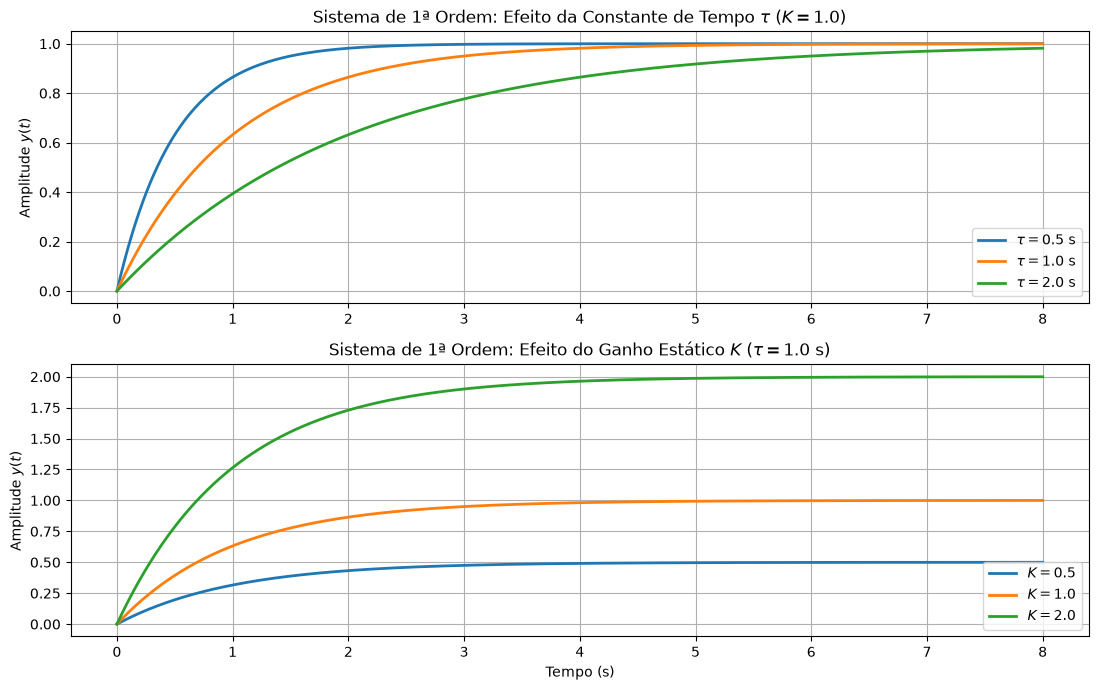

In [2]:
t = np.linspace(0, 8, 1000)

# Experimento 1.1: Variação da Constante de Tempo tau (K = 1.0 fixo)
taus = [0.5, 1.0, 2.0]
fig1, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7))

for tau_i in taus:
    sys = signal.lti([1.0], [tau_i, 1.0])
    _, y = signal.step(sys, T=t)
    ax1.plot(t, y, linewidth=2, label=f'$\\tau = {tau_i}\\text{{ s}}$')

ax1.set_title(r'Sistema de 1ª Ordem: Efeito da Constante de Tempo $\tau$ ($K = 1.0$)')
ax1.set_ylabel('Amplitude $y(t)$')
ax1.grid(True)
ax1.legend(loc='lower right')

# Experimento 1.2: Variação do Ganho Estático K (tau = 1.0 s fixo)
ganhos_K = [0.5, 1.0, 2.0]
for K_i in ganhos_K:
    sys = signal.lti([K_i], [1.0, 1.0])
    _, y = signal.step(sys, T=t)
    ax2.plot(t, y, linewidth=2, label=f'$K = {K_i}$')

ax2.set_title(r'Sistema de 1ª Ordem: Efeito do Ganho Estático $K$ ($\tau = 1.0\text{ s}$)')
ax2.set_xlabel('Tempo (s)')
ax2.set_ylabel('Amplitude $y(t)$')
ax2.grid(True)
ax2.legend(loc='lower right')

plt.tight_layout()
fig1.savefig("grafico_primeira_ordem.png")
plt.show()

## 2. Sistemas de Segunda Ordem: Variação do Fator de Amortecimento $\zeta$ e Frequência Natural $\omega_n$

A função de transferência canônica de segunda ordem é dada por:
$$H(s) = \frac{\omega_n^2}{s^2 + 2\zeta\omega_n s + \omega_n^2}$$

- **Fator de Amortecimento ($\zeta$)**:
  - $\zeta > 1$: Sistema Superamortecido (sem oscilação).
  - $\zeta = 1$: Sistema Criticamente Amortecido (resposta mais rápida sem sobressinal).
  - $0 < \zeta < 1$: Sistema Subamortecido (apresenta sobressinal / *overshoot* e oscilações).
  - $\zeta = 0$: Sistema Não Amortecido (oscilação senoidal contínua).
- **Frequência Natural ($\omega_n$)**: Define a escala de tempo e a frequência de oscilação não amortecida.

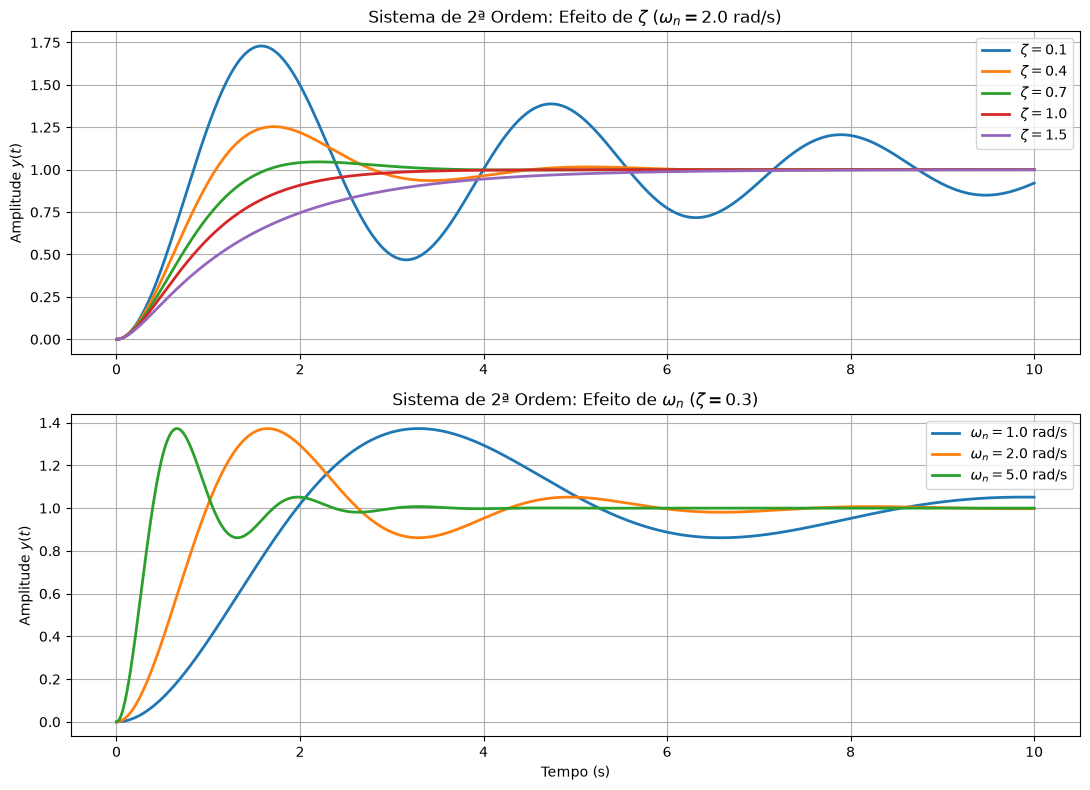

In [3]:
t_2a = np.linspace(0, 10, 1000)

# Experimento 2.1: Variação do Fator de Amortecimento zeta (wn = 2.0 rad/s fixo)
zetas = [0.1, 0.4, 0.7, 1.0, 1.5]
wn_fixo = 2.0

fig2, (ax3, ax4) = plt.subplots(2, 1, figsize=(11, 8))

for zeta_i in zetas:
    num = [wn_fixo**2]
    den = [1.0, 2.0 * zeta_i * wn_fixo, wn_fixo**2]
    sys = signal.lti(num, den)
    _, y = signal.step(sys, T=t_2a)
    ax3.plot(t_2a, y, linewidth=2, label=f'$\\zeta = {zeta_i}$')

ax3.set_title(r'Sistema de 2ª Ordem: Efeito de $\zeta$ ($\omega_n = 2.0\text{ rad/s}$)')
ax3.set_ylabel('Amplitude $y(t)$')
ax3.grid(True)
ax3.legend(loc='upper right')

# Experimento 2.2: Variação da Frequência Natural wn (zeta = 0.3 fixo)
wns = [1.0, 2.0, 5.0]
zeta_fixo = 0.3

for wn_i in wns:
    num = [wn_i**2]
    den = [1.0, 2.0 * zeta_fixo * wn_i, wn_i**2]
    sys = signal.lti(num, den)
    _, y = signal.step(sys, T=t_2a)
    ax4.plot(t_2a, y, linewidth=2, label=f'$\\omega_n = {wn_i}\\text{{ rad/s}}$')

ax4.set_title(r'Sistema de 2ª Ordem: Efeito de $\omega_n$ ($\zeta = 0.3$)')
ax4.set_xlabel('Tempo (s)')
ax4.set_ylabel('Amplitude $y(t)$')
ax4.grid(True)
ax4.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_segunda_ordem.png")
plt.show()

## 3. Síntese dos Resultados sobre Função de Transferência
- **Sistemas de 1ª Ordem**: A constante de tempo $\tau$ dita diretamente a inércia do sistema (quanto maior $\tau$, mais lenta a resposta), enquanto o ganho $K$ dimensiona a amplitude final em regime permanente.
- **Sistemas de 2ª Ordem**: O fator de amortecimento $\zeta$ controla a presença e a intensidade dos transientes oscilatórios (sobressinal). Valores baixos de $\zeta$ ($< 0,7$) produzem picos elevados de sobressinal.
- **Papel da Frequência Natural ($\omega_n$)**: O incremento de $\omega_n$ acelera o tempo de resposta e aumenta a frequência da oscilação transiente no tempo.